In [1]:

import pymc as pm
import pytensor.tensor as pt
import numpy as np
import arviz as az

from models.melodic_markov_model import MelodicMarkovModel
from models.mm_mode_independent_model import MarkovModeIndependentModel
from models.mm_mode_region_independent import MarkovModeRegionIndependent
from data.GradualePipeline import GradualePipeline


/Users/timeipert/PycharmProjects/generative_medieval_music_model/venvnew/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [2]:
data = GradualePipeline.load("data/processed/dataset_pitches_modes.pkl")
data

{'x_0_obs': array([ 6,  7,  7,  2,  6,  3,  7,  5,  6,  3,  5,  5,  5,  3,  5,  3,  3,
         4,  6,  3,  3,  6,  5,  6,  7,  5,  4,  2,  6,  5,  5,  3,  3,  6,
         9,  5,  5,  7,  6,  7,  3,  3,  6,  6,  5,  9,  3,  7,  9,  3,  3,
         5,  3,  6,  8,  6,  8,  6, 10,  6,  5,  3,  9,  6,  9,  8,  6,  5,
         3,  4,  3,  9,  9,  3,  7,  2,  9,  3,  3,  2,  6,  2,  3,  2,  3,
         6,  3,  3,  3,  7,  6,  5,  6,  5,  3,  7,  5,  7,  6,  6,  5,  9,
         6,  3,  5,  3,  7,  5,  7,  7,  3,  4,  5,  9,  9,  3,  3,  4,  9,
         6,  3,  7,  5,  6,  3,  5,  7,  5,  7,  9,  3,  6,  3,  3]),
 'x_t_obs': array([[ 6,  7,  6, ...,  6,  5,  5],
        [ 7,  7,  5, ...,  5,  5,  3],
        [ 8,  6,  6, ...,  5,  6,  3],
        ...,
        [-1, -1, -1, ..., -1, -1, -1],
        [-1, -1, -1, ..., -1, -1, -1],
        [-1, -1, -1, ..., -1, -1, -1]], shape=(428, 134)),
 'lengths_obs': array([385, 201, 104,  80, 222, 211, 140, 158, 219, 279, 260,  98, 145,
        103, 109, 154

In [3]:
data_r = GradualePipeline.load("data/processed/dataset_pitches_modes_regions.pkl")


## Simple Markov Model vs. Markov Independent Mode Model
Building a model comparison with a Hierarchical Dirichlet approach.
Dabei wird ein Hierarchisches Mixture Model gebildet, das die likelihood beider Modelle als Mixture kombiniert.
Die log-likelihoods der beiden Modelle werden zu dem Mixture-Model mit der Zeile zusammengefügt:


    logp_mixture = pm.math.logsumexp(pt.log(w) + pt.stack([ll_base, ll_mode]))







In [12]:

def prepare_sequence_data(initial_states_obs, sequence_states_obs, sequence_lengths_obs):
    initial_states_padded = pt.shape_padleft(initial_states_obs)
    all_states = pt.concatenate([initial_states_padded, sequence_states_obs], axis=0)
    
    prev_states = all_states[:-1]
    current_states = all_states[1:]

    time_indices = pt.arange(sequence_states_obs.shape[0])
    valid_time_mask = time_indices[:, None] < sequence_lengths_obs[None, :]
    
    valid_prev_states = prev_states[valid_time_mask]
    valid_current_states = current_states[valid_time_mask]
    
    return prev_states, current_states, valid_prev_states, valid_current_states, valid_time_mask


def build_mixture_supermodel(initial_states_obs, sequence_states_obs, sequence_lengths_obs, mode_obs):
    m_base = MelodicMarkovModel()
    m_mode = MarkovModeIndependentModel()
    
    with pm.Model() as supermodel:
        # Approach suggested at: https://discourse.pymc.io/t/how-to-do-model-comparison-with-a-dummy-variable/12903/7
        w = pm.Dirichlet("model_weights", a=np.ones(2))
        
        with pm.Model(name="base"):
            base_init_probs, base_transition = m_base._define_priors()
            
        with pm.Model(name="mode"):
            mode_probs, mode_transition, mode_init_probs = m_mode._define_priors()
            
        prev, curr, valid_prev, valid_curr, valid_mask = prepare_sequence_data(
            initial_states_obs, sequence_states_obs, sequence_lengths_obs
        )
        
        init_logp_base = pm.logp(pm.Categorical.dist(p=base_init_probs), initial_states_obs)
        step_logp_base = pm.logp(pm.Categorical.dist(p=base_transition[valid_prev]), valid_curr)
        ll_base = pt.sum(init_logp_base) + pt.sum(step_logp_base)
        
        init_logp_mode = pm.logp(pm.Categorical.dist(p=mode_init_probs), initial_states_obs)
        seq_ll_mode = m_mode._calculate_sequence_logp(prev, curr, valid_mask, mode_transition, mode_obs)
        ll_mode = pt.sum(init_logp_mode) + seq_ll_mode
        
        logp_mixture = pm.math.logsumexp(pt.log(w) + pt.stack([ll_base, ll_mode]))
        pm.Potential("mixture_likelihood", logp_mixture)
    return supermodel


In [13]:

supermodel = build_mixture_supermodel(
    initial_states_obs=data["x_0_obs"], 
    sequence_states_obs=data["x_t_obs"], 
    sequence_lengths_obs=data["lengths_obs"], 
    mode_obs=data["m_obs"]
)


In [15]:

#with supermodel:
#    trace = pm.sample(draws=3000, tune=1000, chains=4, target_accept=0.9)
#trace.to_netcdf("samples/trace_comparison_smm_mode_indep.nc")
import arviz as az

trace = az.from_netcdf("samples/trace_comparison_smm_mode_indep.nc")

Es sieht erst mal alles gut aus. Das Problem ist aber, dass in den verschiedenen Chains die model_weights komplett switchen (beide Kurven haben orange und blaue Linien)

array([[<Axes: title={'center': 'model_weights'}>,
        <Axes: title={'center': 'model_weights'}>]], dtype=object)

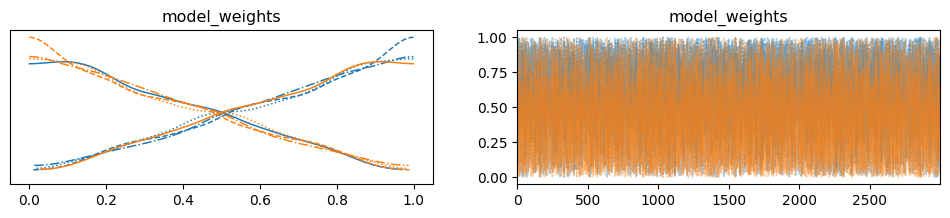

In [16]:
az.plot_trace(trace, var_names=["model_weights"])

In [19]:
trace.posterior.model_weights.values

array([[[0.3653142 , 0.6346858 ],
        [0.06212211, 0.93787789],
        [0.72053588, 0.27946412],
        ...,
        [0.38708134, 0.61291866],
        [0.20907929, 0.79092071],
        [0.39283467, 0.60716533]],

       [[0.97937536, 0.02062464],
        [0.97590967, 0.02409033],
        [0.99191511, 0.00808489],
        ...,
        [0.93865255, 0.06134745],
        [0.99831586, 0.00168414],
        [0.99642579, 0.00357421]],

       [[0.67060744, 0.32939256],
        [0.6822907 , 0.3177093 ],
        [0.85593253, 0.14406747],
        ...,
        [0.79407848, 0.20592152],
        [0.76221646, 0.23778354],
        [0.55574435, 0.44425565]],

       [[0.47868366, 0.52131634],
        [0.99189289, 0.00810711],
        [0.99200685, 0.00799315],
        ...,
        [0.54249001, 0.45750999],
        [0.7722423 , 0.2277577 ],
        [0.54856258, 0.45143742]]], shape=(4, 3000, 2))

## Different approach

With pm.Mixture, näher an dem, wie es im Forum geschrieben ist (https://discourse.pymc.io/t/how-to-do-model-comparison-with-a-dummy-variable/12903/7):

Für x_0 und x_t+1 werden jeweils die zwei verschiedenen Cat-Distributions der beiden Modelle definiert und ein je eine Mixture Distribution erstellt.

In [4]:
import pymc as pm
import numpy as np

def prepare_sequence_data2(initial_states_obs, sequence_states_obs, sequence_lengths_obs, mode_obs):
    initial_states_padded = np.expand_dims(initial_states_obs, axis=0)
    all_states = np.concatenate([initial_states_padded, sequence_states_obs], axis=0)
    
    prev_states = all_states[:-1]
    current_states = all_states[1:]

    time_indices = np.arange(sequence_states_obs.shape[0])
    valid_time_mask = time_indices[:, None] < sequence_lengths_obs[None, :]
    
    valid_prev_states = prev_states[valid_time_mask]
    valid_current_states = current_states[valid_time_mask]
    
    modes_broadcast = np.broadcast_to(mode_obs[None, :], prev_states.shape)
    valid_modes = modes_broadcast[valid_time_mask]
    
    return valid_prev_states, valid_current_states, valid_modes


def build_mixture_supermodel2(initial_states_obs, sequence_states_obs, sequence_lengths_obs, mode_obs):
    m_base = MelodicMarkovModel()
    m_mode = MarkovModeIndependentModel()
    
    valid_prev, valid_curr, valid_modes = prepare_sequence_data2(
        initial_states_obs, sequence_states_obs, sequence_lengths_obs, mode_obs
    )
    
    with pm.Model() as supermodel:
        w = pm.Dirichlet("model_weights", a=np.ones(2))
        
        with pm.Model(name="base"):
            base_init_probs, base_transition = m_base._define_priors()
            
        with pm.Model(name="mode"):
            mode_probs, mode_transition, mode_init_probs = m_mode._define_priors()
            
        init_components = [
            pm.Categorical.dist(p=base_init_probs, shape=initial_states_obs.shape),
            pm.Categorical.dist(p=mode_init_probs, shape=initial_states_obs.shape)
        ]
        
        pm.Mixture(
            "obs_init", 
            w=w, 
            comp_dists=init_components, 
            observed=initial_states_obs
        )
        
        step_components = [
            pm.Categorical.dist(p=base_transition[valid_prev], shape=valid_curr.shape),
            pm.Categorical.dist(p=mode_transition[valid_modes, valid_prev], shape=valid_curr.shape)
        ]
        
        pm.Mixture(
            "obs_steps", 
            w=w, 
            comp_dists=step_components, 
            observed=valid_curr
        )
        
    return supermodel



In [5]:

supermodel2 = build_mixture_supermodel2(
    initial_states_obs=data["x_0_obs"], 
    sequence_states_obs=data["x_t_obs"], 
    sequence_lengths_obs=data["lengths_obs"], 
    mode_obs=data["m_obs"]
)

Zum Testen mit wenig draws:

In [6]:
with supermodel2:
    trace_m2 = pm.sample(draws=500, tune=100, chains=4, target_accept=0.9)
trace_m2.to_netcdf("samples/trace_comparison_smm_mode_indep_mixture_new.nc")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [model_weights, base::init_probs, base::transition_matrix, mode::mode_probs, mode::mode_transition_matrices, mode::init_probs]


Output()

Sampling 4 chains for 100 tune and 500 draw iterations (400 + 2_000 draws total) took 2167 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


'samples/trace_comparison_smm_mode_indep_mixture_new.nc'

In [7]:
trace_m2.posterior

<xarray.Dataset> Size: 47MB
Dimensions:                               (chain: 4, draw: 500,
                                           model_weights_dim_0: 2,
                                           base::init_probs_dim_0: 18,
                                           base::transition_matrix_dim_0: 18,
                                           base::transition_matrix_dim_1: 18,
                                           mode::mode_probs_dim_0: 8,
                                           mode::mode_transition_matrices_dim_0: 8,
                                           mode::mode_transition_matrices_dim_1: 18,
                                           mode::mode_transition_matrices_dim_2: 18,
                                           mode::init_probs_dim_0: 18)
Coordinates:
  * chain                                 (chain) int64 32B 0 1 2 3
  * draw                                  (draw) int64 4kB 0 1 2 ... 497 498 499
  * model_weights_dim_0                   (model_weights_dim_0) int64 16B 0 1
  * base::init_probs_dim_0                (base::init_probs_dim_0) int64 144B ...
  * base::transition_matrix_dim_0         (base::transition_matrix_dim_0) int64 144B ...
  * base::transition_matrix_dim_1         (base::transition_matrix_dim_1) int64 144B ...
  * mode::mode_probs_dim_0                (mode::mode_probs_dim_0) int64 64B ...
  * mode::mode_transition_matrices_dim_0  (mode::mode_transition_matrices_dim_0) int64 64B ...
  * mode::mode_transition_matrices_dim_1  (mode::mode_transition_matrices_dim_1) int64 144B ...
  * mode::mode_transition_matrices_dim_2  (mode::mode_transition_matrices_dim_2) int64 144B ...
  * mode::init_probs_dim_0                (mode::init_probs_dim_0) int64 144B ...
Data variables:
    model_weights                         (chain, draw, model_weights_dim_0) float64 32kB ...
    base::init_probs                      (chain, draw, base::init_probs_dim_0) float64 288kB ...
    base::transition_matrix               (chain, draw, base::transition_matrix_dim_0, base::transition_matrix_dim_1) float64 5MB ...
    mode::mode_probs                      (chain, draw, mode::mode_probs_dim_0) float64 128kB ...
    mode::mode_transition_matrices        (chain, draw, mode::mode_transition_matrices_dim_0, mode::mode_transition_matrices_dim_1, mode::mode_transition_matrices_dim_2) float64 41MB ...
    mode::init_probs                      (chain, draw, mode::init_probs_dim_0) float64 288kB ...
Attributes:
    created_at:                 2026-04-13T08:47:12.233572+00:00
    arviz_version:              0.23.4
    inference_library:          pymc
    inference_library_version:  5.28.1
    sampling_time:              2166.9759817123413
    tuning_steps:               100

Hier sieht das Ergebnis aber noch schlechter aus, der Sampler bleibt von Anfang an auf Model 1.

array([[<Axes: title={'center': 'model_weights'}>,
        <Axes: title={'center': 'model_weights'}>]], dtype=object)

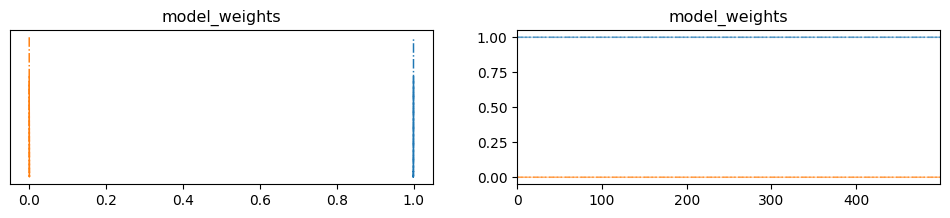

In [12]:
az.plot_trace(trace_m2, var_names=["model_weights"])

## Simple Markov Model vs. Markov Independent Mode & Region Model


In [5]:
def build_region_supermodel(initial_states_obs, sequence_states_obs, sequence_lengths_obs, mode_obs, region_obs):
    m_base = MelodicMarkovModel()
    m_region = MarkovModeRegionIndependent()
    with pm.Model() as supermodel:
        w = pm.Dirichlet("model_weights", a=np.ones(2))
        
        with pm.Model(name="base"):
            base_init_probs, base_transition = m_base._define_priors()
            
        with pm.Model(name="region"):
            mode_probs, region_mode_transition_matrices, region_init_probs = m_region._define_priors()
            
        prev, curr, valid_prev, valid_curr, valid_mask = prepare_sequence_data(
            initial_states_obs, sequence_states_obs, sequence_lengths_obs
        )
        
        init_logp_base = pm.logp(pm.Categorical.dist(p=base_init_probs), initial_states_obs)
        step_logp_base = pm.logp(pm.Categorical.dist(p=base_transition[valid_prev]), valid_curr)
        ll_base = pt.sum(init_logp_base) + pt.sum(step_logp_base)
        
        init_logp_region = pm.logp(pm.Categorical.dist(p=region_init_probs), initial_states_obs)
        seq_ll_region = m_region._calculate_sequence_logp(
            prev, 
            curr, 
            valid_mask, 
            region_mode_transition_matrices, 
            mode_obs, 
            region_obs
        )
        ll_region = pt.sum(init_logp_region) + seq_ll_region
        
        logp_mixture = pm.math.logsumexp(pt.log(w) + pt.stack([ll_base, ll_region]))
        pm.Potential("mixture_likelihood", logp_mixture)
        
    return supermodel

In [6]:
region_supermodel = build_region_supermodel(
    initial_states_obs=data_r["x_0_obs"], 
    sequence_states_obs=data_r["x_t_obs"], 
    sequence_lengths_obs=data_r["lengths_obs"], 
    mode_obs=data_r["m_obs"],
    region_obs=data_r["region_obs"]
)

In [44]:
#with region_supermodel:
#    trace_region = pm.sample(draws=4000, tune=1000, chains=4, target_accept=0.9)
#trace_region.to_netcdf("samples/trace_comparison_smm_regio_indep_two.nc")

trace_region = az.from_netcdf("samples/trace_comparison_smm_regio_indep_two.nc")

array([[<Axes: title={'center': 'model_weights'}>,
        <Axes: title={'center': 'model_weights'}>]], dtype=object)

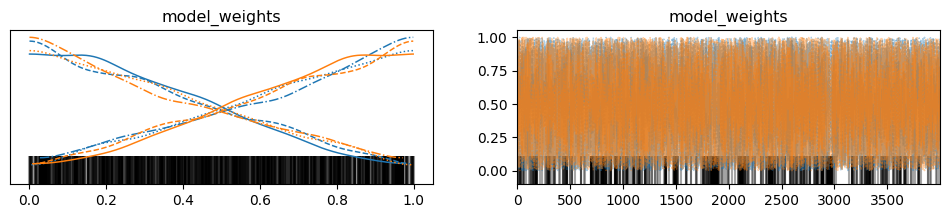

In [45]:
az.plot_trace(trace_region, var_names=["model_weights"])

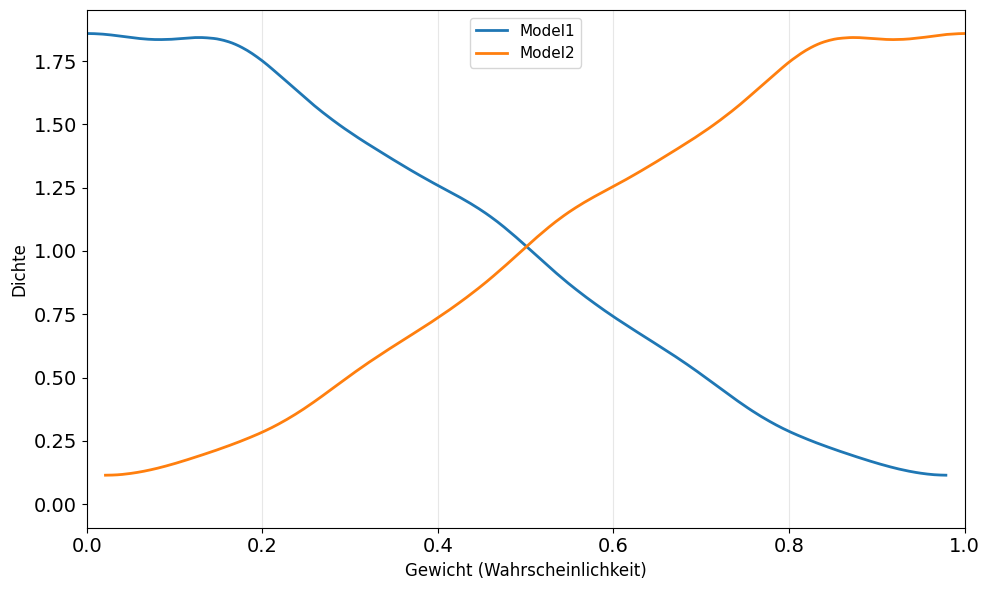

In [47]:

w0_r, w1_r = extract_chain_weights(trace_region)
plot_overlaid_weights(w0_r, w1_r)

Posterior prob Base Model: 0.4967
posterior prob Mode Model: 0.5033

Bayes Factor: 1.0132


## Simple Markov Model vs. Simple Melodic Rules Model



In [1]:

import pymc as pm
import pytensor.tensor as pt
import numpy as np
import arviz as az

from models.melodic_markov_model import MelodicMarkovModel
from models.mm_musical_components2 import MelodicComponentsIIMarkovModel


def prepare_sequence_data(initial_states_obs, sequence_states_obs, sequence_lengths_obs):
    initial_states_padded = pt.shape_padleft(initial_states_obs)
    all_states = pt.concatenate([initial_states_padded, sequence_states_obs], axis=0)
    
    prev_states = all_states[:-1]
    current_states = all_states[1:]

    time_indices = pt.arange(sequence_states_obs.shape[0])
    valid_time_mask = time_indices[:, None] < sequence_lengths_obs[None, :]
    
    valid_prev_states = prev_states[valid_time_mask]
    valid_current_states = current_states[valid_time_mask]
    return prev_states, current_states, valid_prev_states, valid_current_states, valid_time_mask


def build_components_vs_markov_supermodel(initial_states_obs, sequence_states_obs, sequence_lengths_obs):
    m_markov = MelodicMarkovModel()
    m_components = MelodicComponentsIIMarkovModel()
    
    with pm.Model() as supermodel:
        w = pm.Dirichlet("model_weights", a=np.ones(2))

        with pm.Model(name="markov"):
            markov_init_probs, markov_transition = m_markov._define_priors()

        with pm.Model(name="components"):
            comp_init_probs, comp_transition = m_components._define_priors()

        prev, curr, valid_prev, valid_curr, valid_mask = prepare_sequence_data(
            initial_states_obs, sequence_states_obs, sequence_lengths_obs
        )

        init_logp_markov = pm.logp(pm.Categorical.dist(p=markov_init_probs), initial_states_obs)
        step_logp_markov = pm.logp(pm.Categorical.dist(p=markov_transition[valid_prev]), valid_curr)
        ll_markov = pt.sum(init_logp_markov) + pt.sum(step_logp_markov)

        init_logp_comp = pm.logp(pm.Categorical.dist(p=comp_init_probs), initial_states_obs)
        step_logp_comp = pm.logp(pm.Categorical.dist(p=comp_transition[valid_prev]), valid_curr)
        ll_comp = pt.sum(init_logp_comp) + pt.sum(step_logp_comp)

        logp_mixture = pm.math.logsumexp(pt.log(w) + pt.stack([ll_markov, ll_comp]))
        pm.Potential("mixture_likelihood", logp_mixture)
        
    return supermodel


/Users/timeipert/PycharmProjects/generative_medieval_music_model/venvnew/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [8]:
supermodel3 = build_components_vs_markov_supermodel(
    initial_states_obs=data["x_0_obs"], 
    sequence_states_obs=data["x_t_obs"], 
    sequence_lengths_obs=data["lengths_obs"]
)

with supermodel3:
    trace3 = pm.sample(draws=4000, tune=1500, chains=4, target_accept=0.9)

weights = trace3.posterior["model_weights"].values

w_markov_mean = weights[..., 0].mean()
w_comp_mean = weights[..., 1].mean()

print(f"Posteriori-Wahrscheinlichkeit Freies Markov Model: {w_markov_mean:.4f}")
print(f"Posteriori-Wahrscheinlichkeit Components Model:    {w_comp_mean:.4f}")


NameError: name 'build_components_vs_markov_supermodel' is not defined

In [6]:

trace3.to_netcdf("samples/trace_comparison_simple_markov_vs_melodic_componet.nc")

'samples/trace_comparison_simple_markov_vs_melodic_componet.nc'

# Melodic Components vs. Melodic Component + Mode + Regio

In [5]:
import pymc as pm
import pytensor.tensor as pt
import numpy as np
import arviz as az

from models.mm_musical_components2 import MelodicComponentsIIMarkovModel
from models.mm_music_components_region_mode import MelodicComponentsRegionModeModel


def prepare_sequence_data(initial_states_obs, sequence_states_obs, sequence_lengths_obs):
    initial_states_padded = pt.shape_padleft(initial_states_obs)
    all_states = pt.concatenate([initial_states_padded, sequence_states_obs], axis=0)
    
    prev_states = all_states[:-1]
    current_states = all_states[1:]

    time_indices = pt.arange(sequence_states_obs.shape[0])
    valid_time_mask = time_indices[:, None] < sequence_lengths_obs[None, :]
    
    valid_prev_states = prev_states[valid_time_mask]
    valid_current_states = current_states[valid_time_mask]
    
    return prev_states, current_states, valid_prev_states, valid_current_states, valid_time_mask


def build_mixture_supermodel(initial_states_obs, sequence_states_obs, sequence_lengths_obs, mode_obs, region_obs):
    m_base = MelodicComponentsIIMarkovModel()
    m_complex = MelodicComponentsRegionModeModel()
    
    with pm.Model() as supermodel:
        w = pm.Dirichlet("model_weights", a=np.ones(2))

        with pm.Model(name="base"):
            base_init_probs, base_transition = m_base._define_priors()

        with pm.Model(name="complex"):
            complex_init_probs, complex_transition, _ = m_complex._define_priors(use_modes=True, use_regions=True)

        # 2. Daten maskieren
        prev, curr, valid_prev, valid_curr, valid_mask = prepare_sequence_data(
            initial_states_obs, sequence_states_obs, sequence_lengths_obs
        )

        init_logp_base = pm.logp(pm.Categorical.dist(p=base_init_probs), initial_states_obs)
        step_logp_base = pm.logp(pm.Categorical.dist(p=base_transition[valid_prev]), valid_curr)
        ll_base = pt.sum(init_logp_base) + pt.sum(step_logp_base)

        init_logp_complex = pm.logp(pm.Categorical.dist(p=complex_init_probs), initial_states_obs)
        
        sequence_indices = pt.arange(sequence_states_obs.shape[1])[None, :]
        broadcasted_sequence_indices = pt.alloc(sequence_indices, prev.shape[0], prev.shape[1])
        valid_sequence_indices = broadcasted_sequence_indices[valid_mask]

        region_obs_pt = pt.as_tensor_variable(region_obs)
        mode_obs_pt = pt.as_tensor_variable(mode_obs)

        valid_transition_probs_complex = complex_transition[
            region_obs_pt[valid_sequence_indices], 
            mode_obs_pt[valid_sequence_indices], 
            valid_prev
        ]
        
        step_logp_complex = pm.logp(pm.Categorical.dist(p=valid_transition_probs_complex), valid_curr)
        
        # IMPORTANT! without mode_obs and regio_obs likelihood!
        ll_complex = pt.sum(init_logp_complex) + pt.sum(step_logp_complex)

        logp_mixture = pm.math.logsumexp(pt.log(w) + pt.stack([ll_base, ll_complex]))
        pm.Potential("mixture_likelihood", logp_mixture)
        
    return supermodel


In [7]:
supermodel4 = build_mixture_supermodel(
    initial_states_obs=data_r["x_0_obs"], 
    sequence_states_obs=data_r["x_t_obs"], 
    sequence_lengths_obs=data_r["lengths_obs"], 
    mode_obs=data_r["m_obs"],
    region_obs=data_r["region_obs"] 
)

with supermodel4:
    trace4 = pm.sample(draws=4000, tune=1500, chains=4, target_accept=0.9)

trace4.to_netcdf("samples/trace_comparison_mus_compo_to_mus_compo_region.nc")

weights4 = trace4.posterior["model_weights"].values

w_base_mean4 = weights4[..., 0].mean()
w_complex_mean4 = weights4[..., 1].mean()

print(f"Posteriori-Wahrscheinlichkeit Base Model:   {w_base_mean4:.4f}")
print(f"Posteriori-Wahrscheinlichkeit Region/Mode Model: {w_complex_mean4:.4f}")


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [model_weights, base::init_probs, base::weight_interval, base::register_center, base::weight_register, base::weight_repeat, base::weight_direction, complex::weight_interval, complex::weight_register, complex::weight_repeat, complex::weight_direction, complex::register_center, complex::init_probs, complex::global_mode_probs, complex::mode_probs_kappa, complex::mode_probs]


Output()

Sampling 4 chains for 1_500 tune and 4_000 draw iterations (6_000 + 16_000 draws total) took 31392 seconds.
There were 509 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Posteriori-Wahrscheinlichkeit Base Model:   0.5014
Posteriori-Wahrscheinlichkeit Region/Mode Model: 0.4986

Bayes Factor (BF_10): 0.9945
-> Evidenz spricht für das Base Model.
